## IEEE-CIS Fraud Detection

This notebook builds a fraud detection model on transaction data from the Kaggle competition https://www.kaggle.com/competitions/ieee-fraud-detection. Key parts of our implemention include

- feature engineering by aggregating transaction data by a synthetic user ID
- dimension reduction by clustering redundant features using Spearman correlation
- exploratory data analysis for finding identifying features and fradulent patterns across users

A key difference with other notebooks from this competition is that we ensure our model can only see features that could be computed "in real time". For instance, aggregations are computed cumulatively, and encodings only see the training set.

Using XGBoost, we achieve a ROC-AUC score of 0.942 on public test set and 0.912 on private test set. Given the class imbalance (only ~3.5% of transactions were fradulent), we acknowledge that ROC-AUC is not the most practical metric for fraud. As a future step, we aim to optimize for more practical metrics, such as PR-AUC or dollar-weighted metrics.

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

In [2]:
# silence performance warnings for fragmented dataframes
import warnings
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

In [3]:
import os
import kagglehub

if os.path.exists('/kaggle/input'): # kaggle notebook
    path = '/kaggle/input/ieee-fraud-detection'
else: # local notebook
    path = kagglehub.competition_download('ieee-fraud-detection')
    print("Path to competition files:", path)

train_id = pd.read_csv(f'{path}/train_identity.csv')
train_tr = pd.read_csv(f'{path}/train_transaction.csv')
test_id = pd.read_csv(f'{path}/test_identity.csv')
test_tr = pd.read_csv(f'{path}/test_transaction.csv')
sub = pd.read_csv(f'{path}/sample_submission.csv')

/Users/eric/projects/kaggle/ieee-cis-fraud-detection/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to competition files: /Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection


In [4]:
print("Number of training samples:", len(train_tr))
print(f"Proportion of fraudulent samples: {train_tr['isFraud'].mean():.4f}")

Number of training samples: 590540
Proportion of fraudulent samples: 0.0350


As expected, there is a significant class imbalance in that only 3.5% of transactions are fraudulent. This suggests using a metric that is more robust to class imbalance, such as PR-AUC, but for now we will use ROC-AUC since that is the competition's standard.

In [5]:
train_tr.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
train_id.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [7]:
# fix labeling inconsistency in test id columns
test_id.rename(columns=dict([(f'id-{n:02d}', f'id_{n:02d}') for n in range(1, 39)]), inplace=True)

# merge id and transaction data
def merge_tr_id_data(df_tr, df_id):
    df_tr = df_tr.set_index('TransactionID', drop=True)
    df_id = df_id.set_index('TransactionID', drop=True)
    df = df_tr.join(df_id, how='left')
    df['has_identity'] = df['id_01'].notna()
    return df

train = merge_tr_id_data(train_tr, train_id)
test = merge_tr_id_data(test_tr, test_id)

In [8]:
# convert float64 to float32 to save memory
float64_cols = train.select_dtypes(include='float64').columns
train[float64_cols] = train[float64_cols].astype('float32')
test[float64_cols] = test[float64_cols].astype('float32')

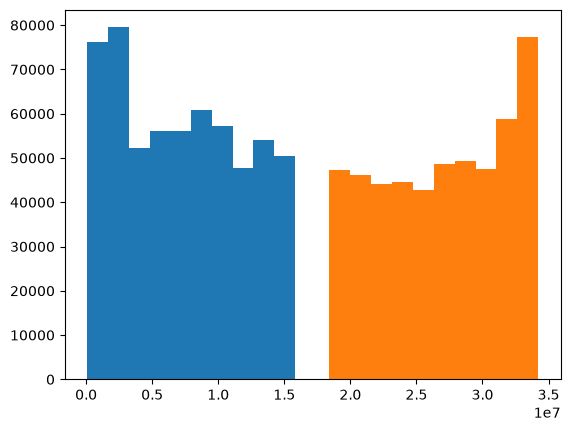

In [9]:
plt.hist(train['TransactionDT'])
plt.hist(test['TransactionDT'])
plt.show()

Given the transaction date ranges are disjoint for the train and test sets, it makes sense to split by date for training and validation to avoid leakage.

In [10]:
N_valid = int(0.2 * len(train))
validation = train.iloc[(-N_valid):]
train = train.iloc[:(-N_valid)]

# Feature engineering

## Time and Seasonality

We don't want to keep track of time itself, since this will drift from training to test time. However, we can use the timestamp to capture seasonality effects by tracking hour / day / weekday. For example, many routine financial transactions occur during business hours or at particular times of the month, so it may be useful for the model to have such context.

Moreover, the D1-D15 columns track days since some previous time, so we normalize these to avoid drift.

In [11]:
D_cols = [f'D{n}' for n in range(1,16)]

def populate_datetime_columns(df):
    df.rename(columns={'TransactionDT': 'ts'}, inplace=True)
    df['TransactionDT'] = pd.to_datetime(df['ts'], unit='s')
    df['day'] = df['TransactionDT'].dt.day
    df['weekday'] = df['TransactionDT'].dt.dayofweek
    df['hour'] = df['TransactionDT'].dt.hour

    # normalize D columns
    for col in D_cols:
        df[f'{col}n'] = (df['ts'] // 86400) - df[col]

train_ = train.copy() # our functions modify in place, so work on a copy of train first
populate_datetime_columns(train_)

## Aggregations by User ID

Here we aggregate transaction history by user. The idea to build a synthetic user ID comes from the [winning solution](https://www.kaggle.com/code/cdeotte/xgb-fraud-with-magic-0-9600) by Chris Deotte. However, a key difference with other solutions is that we only aggregate _prior_ transaction history, as opposed to aggregating over the entire train and test dataset. This is so that we only use information available at transaction time, so that the model could feasibly run in real time. 

Let's motivate the idea. One may expect fraudulent behavior to be mostly consistent per user (we'll see this validated below in our decomposition of fraud behavior by user). 

### Constructing a User ID

The obstacle is that we are not given user IDs! Instead, we can proceed by combining features that serve as a reasonable proxy or 'synthetic user ID.' Reasonable choices are features which (1) remain constant for each user and (2) have high enough cardinalities to distinguish many different users. Let's start by getting a sense of what kind of categorical features we have access to.

In [12]:
categories_tr = ['ProductCD', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain'] 
categories_tr += [f'card{n}' for n in range(1, 7)] + [f'M{n}' for n in range(1,10)]
categories_id = ['DeviceType', 'DeviceInfo'] + [f'id_{n}' for n in range(12,39)] + ['has_identity']
categories = categories_tr + categories_id

# Show cardinalities for categorical features
num_values = train[categories].nunique()
for cat in categories:
    print(cat, num_values[cat], [str(val) for val in train[cat].unique()[:5]])

ProductCD 5 ['W', 'H', 'C', 'S', 'R']
addr1 328 ['315.0', '325.0', '330.0', '476.0', '420.0']
addr2 70 ['87.0', 'nan', '96.0', '35.0', '60.0']
P_emaildomain 59 ['nan', 'gmail.com', 'outlook.com', 'yahoo.com', 'mail.com']
R_emaildomain 60 ['nan', 'gmail.com', 'hotmail.com', 'outlook.com', 'anonymous.com']
card1 12730 ['13926', '2755', '4663', '18132', '4497']
card2 500 ['nan', '404.0', '490.0', '567.0', '514.0']
card3 106 ['150.0', '117.0', '185.0', '143.0', '144.0']
card4 4 ['discover', 'mastercard', 'visa', 'american express', 'nan']
card5 113 ['142.0', '102.0', '166.0', '117.0', '226.0']
card6 4 ['credit', 'debit', 'nan', 'debit or credit', 'charge card']
M1 2 ['T', 'nan', 'F']
M2 2 ['T', 'nan', 'F']
M3 2 ['T', 'nan', 'F']
M4 3 ['M2', 'M0', 'nan', 'M1']
M5 2 ['F', 'T', 'nan']
M6 2 ['T', 'F', 'nan']
M7 2 ['nan', 'F', 'T']
M8 2 ['nan', 'F', 'T']
M9 2 ['nan', 'F', 'T']
DeviceType 2 ['nan', 'mobile', 'desktop']
DeviceInfo 1639 ['nan', 'SAMSUNG SM-G892A Build/NRD90M', 'iOS Device', 'Windo

We see that card1 has 12730 unique values, and addresses should also remain roughly constant per user. Other Kagglers also identified that D1 represents the number of days since account opening. We note that D1n, the difference between D1 and the transaction date, should be constant for each cardholder, so this is also a good identifying feature. 

Given candidates for identifying columns, we can test the 'purity' of a synthetic ID by tracking how often groups have a unique value for other features that should be roughly constant per consumer. 

In [13]:
def summarize_uid(df, id_cols, attrs=('P_emaildomain', 'DeviceInfo', 'id_19', 'id_20', 'id_21')):
    print("UID cols:", id_cols)
    g = df.groupby(id_cols, dropna=False)
    print("Number of UIDs:", len(g))
    print("Purity:", {c: float((g[c].nunique()[g.size() > 1] <= 1).mean().round(4)) for c in attrs})
    print("")

for cols in [
        ['card1'], 
        ['addr1'],
        ['card1', 'addr1'],
        ['card1', 'D1n'],
        ['D1n', 'addr1'],
        ['card1', 'addr1', 'D1n']
    ]:
    summarize_uid(train_, cols)


UID cols: ['card1']
Number of UIDs: 12730
Purity: {'P_emaildomain': 0.2797, 'DeviceInfo': 0.6284, 'id_19': 0.5693, 'id_20': 0.6095, 'id_21': 0.9689}

UID cols: ['addr1']
Number of UIDs: 329
Purity: {'P_emaildomain': 0.2537, 'DeviceInfo': 0.4927, 'id_19': 0.3659, 'id_20': 0.3512, 'id_21': 0.722}

UID cols: ['card1', 'addr1']
Number of UIDs: 36593
Purity: {'P_emaildomain': 0.3765, 'DeviceInfo': 0.7378, 'id_19': 0.6951, 'id_20': 0.786, 'id_21': 0.9846}

UID cols: ['card1', 'D1n']
Number of UIDs: 125908
Purity: {'P_emaildomain': 0.5996, 'DeviceInfo': 0.8673, 'id_19': 0.8282, 'id_20': 0.8433, 'id_21': 0.9976}

UID cols: ['D1n', 'addr1']
Number of UIDs: 23705
Purity: {'P_emaildomain': 0.3017, 'DeviceInfo': 0.7618, 'id_19': 0.74, 'id_20': 0.7937, 'id_21': 0.9776}

UID cols: ['card1', 'addr1', 'D1n']
Number of UIDs: 182535
Purity: {'P_emaildomain': 0.7124, 'DeviceInfo': 0.9044, 'id_19': 0.8719, 'id_20': 0.9101, 'id_21': 0.9994}



It seems that the combination of card1, addr1, and D1n (essentially the date of account opening) identifies many distinct users with a reasonably high purity score for email domain and device. Let's make that our UID, and look at transaction and fraud patterns by user.

In [14]:
def populate_uid(df):
    df['uid'] = df['card1'].astype(str) + '_' + df['addr1'].astype(str) + '_' + df['D1n'].astype(str)

populate_uid(train_)
df = train_[['TransactionDT', 'isFraud', 'uid']]
g = df.groupby('uid')['isFraud']

summary = pd.DataFrame({'n_transactions': g.size(), 'n_fraud': g.sum()})

print("Number of UIDs:", len(g))
print("Total number of fraudulent transactions:", df['isFraud'].sum())
print("Total number of UIDs with any fraud history:", (summary.n_fraud > 0).sum())

single = summary[summary.n_transactions == 1]
multi = summary[summary.n_transactions > 1]
print(f"\nNumber of UIDs with single transaction: {len(single)} | {(single.n_fraud > 0).sum()} with fraud")
print(f"Number of UIDs with multiple transactions: {len(multi)} | {(multi.n_fraud > 0).sum()} with any fraud")

all_fr = multi[multi.n_fraud == multi.n_transactions]
mixed = multi[(multi.n_fraud > 0) & (multi.n_fraud < multi.n_transactions)]
print("\nMulti UIDs with all fraud:", len(all_fr), "users |", all_fr.n_fraud.sum(), "transactions")
print("Multi UIDs with mixed fraud history:", len(mixed), "users |", 
      mixed.n_transactions.sum(), "transactions |", mixed.n_fraud.sum(), "fraud")

print(f"\nProportion of UIDs with any fraud history that have mixed history: {len(mixed) / (summary.n_fraud > 0).sum():.1%}")
print(f"Proportion of fraudulent transactions by 'mixed history' users: {mixed.n_fraud.sum() / df['isFraud'].sum():.1%}")

Number of UIDs: 167111
Total number of fraudulent transactions: 16599
Total number of UIDs with any fraud history: 4015

Number of UIDs with single transaction: 98054 | 1781 with fraud
Number of UIDs with multiple transactions: 69057 | 2234 with any fraud

Multi UIDs with all fraud: 1223 users | 5900 transactions
Multi UIDs with mixed fraud history: 1011 users | 7768 transactions | 2777 fraud

Proportion of UIDs with any fraud history that have mixed history: 25.2%
Proportion of fraudulent transactions by 'mixed history' users: 16.7%


The majority of users have only a single transaction recorded, and of those with multiple transactions, the majority had only fraudulent transactions. Ultimately, the fact that only 16.7% of fraud was transacted by 'mixed history' users suggests that the task at hand is to detect fraudulent *users* rather than fraudulent transactions. Moreover, some of the mixed history may be attributed to several users still being grouped together within the same UID, so the true proportion of 'mixed' fraud is likely less than 16.7%.

Now let's get to building aggregations! We define two types:
1. For identifying features we used earlier to score purity, we add the running number of unique values per user ID group to assist the model in identifying IDs that encompass several users. 
2. For predictive features, we aggregate their cumulative mean and std over user ID. We select the features based on the most important features, which we determine from a previous dry run.

In [15]:
def populate_aggregations(df):
    # running number of unique col values per uid
    for col in ['P_emaildomain', 'DeviceInfo', 'id_19', 'id_20', 'id_21']:
        first_seen = ~df.duplicated(['uid', col]) & df[col].notna()
        df[f'{col}_nunique'] = first_seen.astype(int).groupby(df['uid']).cumsum()

    # aggregating mean and std for important columns
    gb = df.groupby('uid')
    df['time_since_last'] = gb['ts'].diff()
    for col in (
        ['TransactionAmt', 'time_since_last'] +
        [f'C{n}' for n in range(1,15)] +
        ['V45', 'V70', 'V258', 'V317', 'V201', 'V243', 'V246']
    ):
        stats = gb[col].expanding().agg(['mean', 'std']).droplevel('uid')
        df[f'{col}_cummean'] = stats['mean']
        df[f'{col}_cumstd'] = stats['std']

In [16]:
full = pd.concat([train, validation, test])
populate_datetime_columns(full)
populate_uid(full)
populate_aggregations(full)
train, validation, test = full.loc[train.index], full.loc[validation.index], full.loc[test.index]
del full

# Dimension reduction

Here we aim to reduce the dimension of our dataset by eliminating redundant features. The majority of features are the V1-V339 columns, which we see below are grouped into 14 blocks by their nan frequencies, suggesting there may be redundancy. 

Within each block, we keep one representative per cluster of Spearman correlation above a reasonably high threshold such as 0.9, which ultimately cuts the number of V columns in half. 

In [17]:
# here we only group by the number of missing values, 
# but independently have verified the masks are identical within each group
V_cols = [f'V{n}' for n in range(1,340)]
V_isna = train[V_cols].isna()
grouped = V_isna.columns.groupby(V_isna.sum())
V_blocks = []
for count, cols in grouped.items():
    V_blocks.append(list(cols))
    print(count, list(cols))

12 ['V279', 'V280', 'V284', 'V285', 'V286', 'V287', 'V290', 'V291', 'V292', 'V293', 'V294', 'V295', 'V297', 'V298', 'V299', 'V302', 'V303', 'V304', 'V305', 'V306', 'V307', 'V308', 'V309', 'V310', 'V311', 'V312', 'V316', 'V317', 'V318', 'V319', 'V320', 'V321']
97 ['V95', 'V96', 'V97', 'V98', 'V99', 'V100', 'V101', 'V102', 'V103', 'V104', 'V105', 'V106', 'V107', 'V108', 'V109', 'V110', 'V111', 'V112', 'V113', 'V114', 'V115', 'V116', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122', 'V123', 'V124', 'V125', 'V126', 'V127', 'V128', 'V129', 'V130', 'V131', 'V132', 'V133', 'V134', 'V135', 'V136', 'V137']
936 ['V281', 'V282', 'V283', 'V288', 'V289', 'V296', 'V300', 'V301', 'V313', 'V314', 'V315']
66427 ['V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34']
66890 ['V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V7

In [18]:
def select_block_representatives(df, block, threshold=0.9, sample=100000, seed=0):
    # within a block rows are all-observed or all-missing, so dropna keeps the observed rows
    sub = df[block].dropna()
    if len(sub) > sample:
        sub = sub.sample(sample, random_state=seed)
    nunique = sub.nunique()
    # drop constant columns and sort by decreasing cardinality
    candidates = nunique[nunique > 1].sort_values(ascending=False).index 
    # Spearman: trees only see the ordering of a feature, so monotone relationships are redundancy
    corr = sub[candidates].corr(method='spearman').abs()
    reps, covered = [], set()
    for col in candidates:
        if col not in covered:
            reps.append(col)
            covered.update(corr.index[corr[col] >= threshold])
    return reps

keep_V = [c for b in V_blocks for c in select_block_representatives(train, b)]
drop_V = [c for c in V_cols if c not in keep_V]
print("Number of V features kept:", len(keep_V))

Number of V features kept: 176


# Encoding Categorical Features

XGBoost natively supports categorical encodings, but for the sake of comparison with Random Forest, we encode the features from scratch. We use ordinal encoding for binary variables, one hot encoding for low-cardinality variables ($\leq 5$), and frequency encoding for large-cardinality variables. For the frequency encoding, we will only use frequencies from the training set to avoid leakage.

In [19]:
binary_categories = [cat for cat in categories if num_values[cat] == 2]
# use one hot encoding when number of unique values is between 3 and 5
onehot_categories = [cat for cat in categories if num_values[cat] > 2 and num_values[cat] <= 5]
# otherwise use label or frequency encoding
numerous_categories = [cat for cat in categories if num_values[cat] > 5]

print('Binary categories:', binary_categories)
print('One-hot categories:', onehot_categories)
print('Numerous categories:', numerous_categories)

Binary categories: ['M1', 'M2', 'M3', 'M5', 'M6', 'M7', 'M8', 'M9', 'DeviceType', 'id_12', 'id_16', 'id_27', 'id_28', 'id_29', 'id_35', 'id_36', 'id_37', 'id_38', 'has_identity']
One-hot categories: ['ProductCD', 'card4', 'card6', 'M4', 'id_15', 'id_23', 'id_32', 'id_34']
Numerous categories: ['addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'card1', 'card2', 'card3', 'card5', 'DeviceInfo', 'id_13', 'id_14', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_24', 'id_25', 'id_26', 'id_30', 'id_31', 'id_33']


In [20]:
oe = OrdinalEncoder()
train[binary_categories] = oe.fit_transform(train[binary_categories])

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(train[onehot_categories])

def ohe_transform(df, categories, ohe):
    encoded_array = ohe.transform(df[categories])
    encoded_df = pd.DataFrame(encoded_array, columns=ohe.get_feature_names_out(categories), index=df.index)
    return pd.concat([df.drop(columns=categories), encoded_df], axis=1)

train = ohe_transform(train, onehot_categories, ohe)
train.head()

,isFraud,ts,TransactionAmt,card1,card2,card3,card5,addr1,addr2,dist1,...,id_32_0.0,id_32_16.0,id_32_24.0,id_32_32.0,id_32_nan,id_34_match_status:-1,id_34_match_status:0,id_34_match_status:1,id_34_match_status:2,id_34_nan
TransactionID,,,,,,,,,,,,,,,,,,,,,
2987000,0.0,86400,68.5,13926,NaN,150.0,142.0,315.0,87.0,19.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987001,0.0,86401,29.0,2755,404.0,150.0,102.0,325.0,87.0,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987002,0.0,86469,59.0,4663,490.0,150.0,166.0,330.0,87.0,287.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987003,0.0,86499,50.0,18132,567.0,150.0,117.0,476.0,87.0,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987004,0.0,86506,50.0,4497,514.0,150.0,102.0,420.0,87.0,NaN,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [21]:
# frequency encoding for high-cardinality categorical features
# only count frequencies in training set
freq_map = {}
for cat in numerous_categories:
    freq_dict = train[cat].value_counts(normalize=True).to_dict()
    train[cat] = train[cat].map(freq_dict)
    freq_map[cat] = freq_dict

train[numerous_categories].head()

,addr1,addr2,P_emaildomain,R_emaildomain,card1,card2,card3,card5,DeviceInfo,id_13,...,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_30,id_31,id_33
TransactionID,,,,,,,,,,,,,,,,,,,,,
2987000,0.044032,0.990611,NaN,NaN,0.000089,NaN,0.881741,0.000482,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987001,0.081355,0.990611,0.458051,NaN,0.001207,0.005552,0.881741,0.047571,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987002,0.047355,0.990611,0.010230,NaN,0.001875,0.064821,0.881741,0.097132,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987003,0.018274,0.990611,0.202720,NaN,0.007161,0.010582,0.881741,0.043497,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987004,0.006814,0.990611,0.458051,NaN,0.000028,0.025339,0.881741,0.047571,0.00009,NaN,...,0.03863,0.005093,NaN,NaN,NaN,NaN,NaN,0.040188,0.009024,0.007215


In [22]:
# given oe, ohe, and freq_dict, apply all encoding transformations to df
def encode_categorical_features(df):
    df[binary_categories] = oe.transform(df[binary_categories])
    df = ohe_transform(df, onehot_categories, ohe)
    for cat in numerous_categories:
        df[cat] = df[cat].map(freq_map[cat])
    return df

validation = encode_categorical_features(validation)
test = encode_categorical_features(test)

In [23]:
# drop unnecessary columns
drop_columns = drop_V + ['TransactionDT', 'ts', 'uid']
train.drop(columns=drop_columns, inplace=True)
validation.drop(columns=drop_columns, inplace=True)
test.drop(columns=drop_columns, inplace=True)

# copy to reset any internal fragmentation
train = train.copy()
validation = validation.copy()
test = test.copy()

# Training and Validation

Now we've finished feature construction and data preparation, we're ready to train a model. Given the large frequency of missing data fields, we'll use tree ensemble models. Let's compare Random Forest and XGBoost.

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_recall_curve

In [25]:
y_train = train['isFraud']
X_train = train.drop(columns=['isFraud'])
y_valid = validation['isFraud']
X_valid = validation.drop(columns=['isFraud'])
X_test = test.drop(columns=['isFraud'])
assert list(X_test.columns) == list(X_train.columns)

In [26]:
def plot_roc(X, y, classifier):
    y_score = classifier.predict_proba(X)[:, 1]
    print(f"ROC AUC: {roc_auc_score(y, y_score):.4f}")

    fpr, tpr, _ = roc_curve(y, y_score)
    plt.figure(figsize=(4, 3))
    plt.plot(fpr, tpr, label='ROC curve')
    plt.plot([0, 1], [0, 1], 'k--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()

def plot_pr(X, y, classifier):
    y_score = classifier.predict_proba(X)[:, 1]
    print(f"Average Precision: {average_precision_score(y, y_score):.4f}")

    p, r, _ = precision_recall_curve(y, y_score)
    plt.figure(figsize=(4, 3))
    plt.plot(r, p, label='Precision-Recall curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('PR Curve')
    plt.legend()
    plt.show()

## Random Forest

In [27]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5
).fit(X_train, y_train)

Random Forest Performance on Training Set
ROC AUC: 0.9583


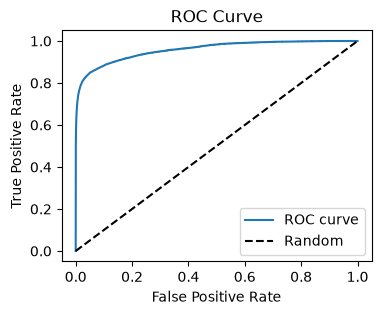

Random Forest Performance on Validation Set
ROC AUC: 0.8896


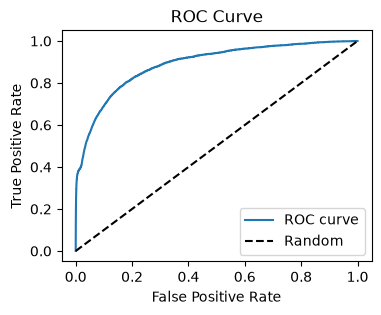

In [28]:
print("Random Forest Performance on Training Set")
plot_roc(X_train, y_train, rf_classifier)

print("Random Forest Performance on Validation Set")
plot_roc(X_valid, y_valid, rf_classifier)

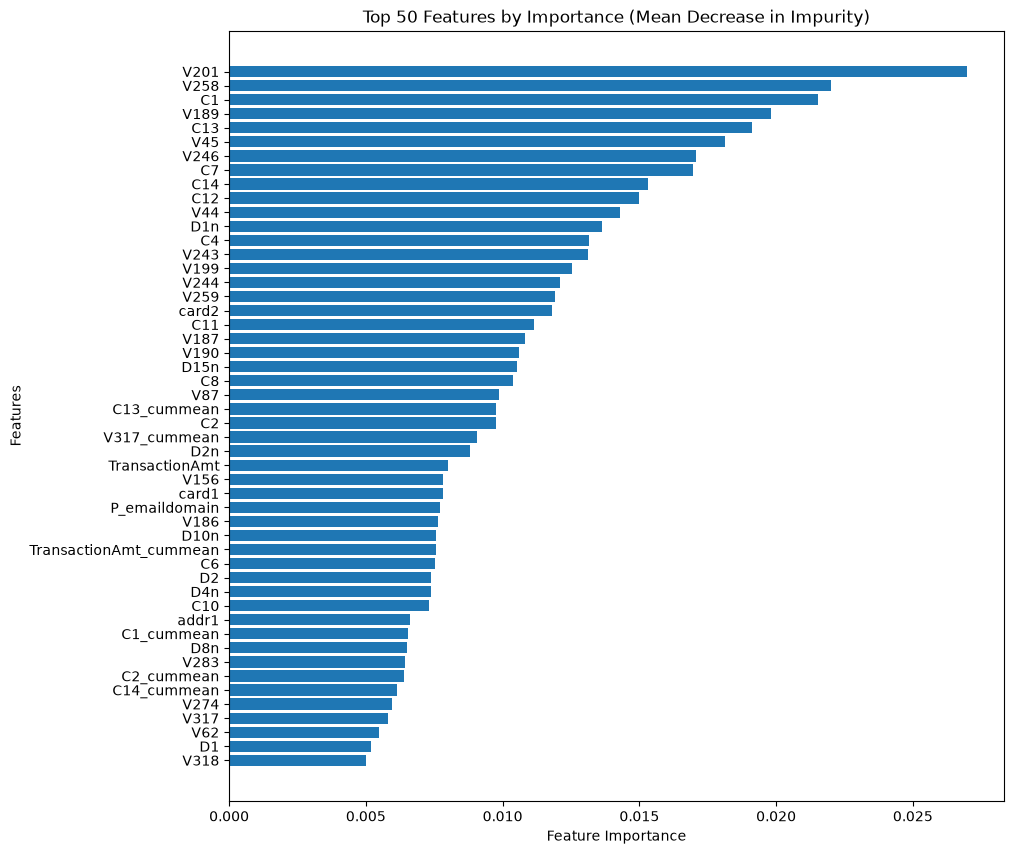

In [29]:
# plot important features
importances = rf_classifier.feature_importances_
indices = np.argsort(importances)
sorted_features = X_train.columns[indices]
sorted_importances = importances[indices]

N = 50
plt.figure(figsize=(10, 10))
plt.barh(sorted_features[-N:], sorted_importances[-N:], align='center')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title(f'Top {N} Features by Importance (Mean Decrease in Impurity)')
plt.show()


## XGBoost

In [30]:
import xgboost as xgb

xgb_classifier = xgb.XGBClassifier(
    n_estimators=2000,
    learning_rate=0.02,
    early_stopping_rounds=200,
    max_depth=10,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc'
).fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=100)

[0]	validation_0-auc:0.82604
[100]	validation_0-auc:0.89774
[200]	validation_0-auc:0.91387
[300]	validation_0-auc:0.92049
[400]	validation_0-auc:0.92396
[500]	validation_0-auc:0.92579
[600]	validation_0-auc:0.92762
[700]	validation_0-auc:0.92895
[800]	validation_0-auc:0.92977
[900]	validation_0-auc:0.93036
[1000]	validation_0-auc:0.93061
[1100]	validation_0-auc:0.93032
[1200]	validation_0-auc:0.93021
[1210]	validation_0-auc:0.93016


XGBoost Performance on Training Set
ROC AUC: 0.9913


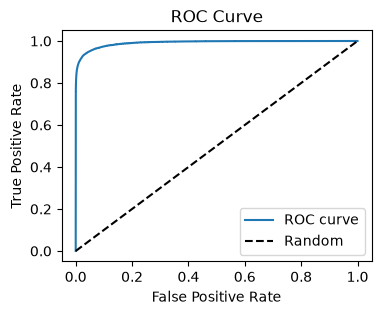

XGBoost Performance on Validation Set
ROC AUC: 0.9307


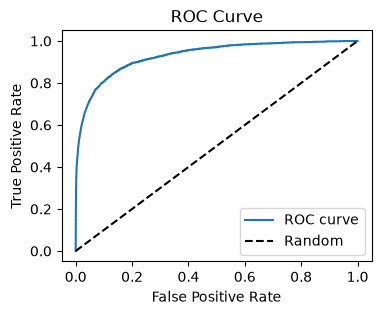

In [31]:
print("XGBoost Performance on Training Set")
plot_roc(X_train, y_train, xgb_classifier)

print("XGBoost Performance on Validation Set")
plot_roc(X_valid, y_valid, xgb_classifier)

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

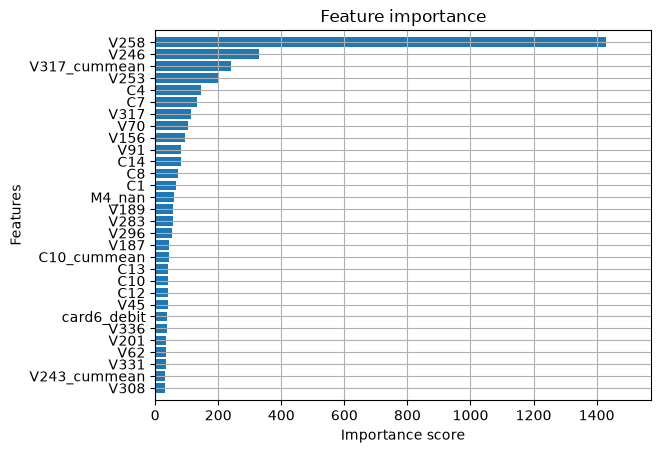

In [32]:
from xgboost import plot_importance
plot_importance(xgb_classifier, 
                max_num_features=30, 
                importance_type='gain', 
                show_values=False,
                height=0.8)

# Final model and submission

Now we refit on training + validation. The number of trees comes from early stopping on validation, scaled up because train + validation is 1/0.8 = 1.25x the data.

In [33]:
n_final = int(xgb_classifier.best_iteration * 1.25)
print('Best iteration:', xgb_classifier.best_iteration, '| final n_estimators:', n_final)

final_classifier = xgb.XGBClassifier(**{
    **xgb_classifier.get_params(),
    'n_estimators': n_final,
    'early_stopping_rounds': None,
}).fit(pd.concat([X_train, X_valid]), pd.concat([y_train, y_valid]))

Best iteration: 1010 | final n_estimators: 1262


In [34]:
sub = pd.read_csv(f'{path}/sample_submission.csv')
sub['isFraud'] = final_classifier.predict_proba(X_test.loc[sub['TransactionID']])[:, 1]
sub.to_csv('submission.csv', index=False)
sub.head()

,TransactionID,isFraud
0,3663549,0.000978
1,3663550,0.001253
2,3663551,0.002628
3,3663552,0.007615
4,3663553,0.001938


# Future Directions
Optimize for more practical metrics, such as PR-AUC to account for the class imbalance, or dollar-weighted loss.

XGBoost PR on Training Set
Average Precision: 0.9292


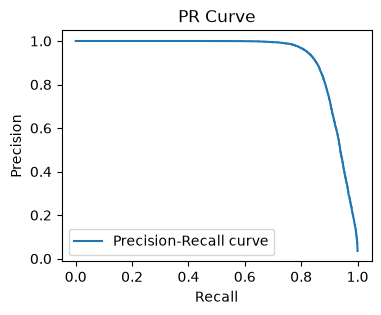

XGBoost PR on Validation Set
Average Precision: 0.5978


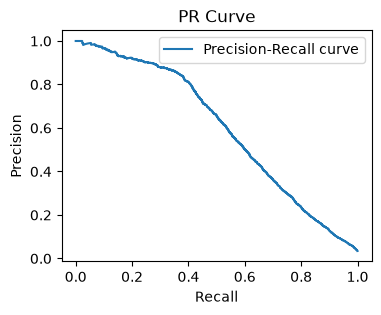

In [35]:
print("XGBoost PR on Training Set")
plot_pr(X_train, y_train, xgb_classifier)

print("XGBoost PR on Validation Set")
plot_pr(X_valid, y_valid, xgb_classifier)